<a href="https://colab.research.google.com/github/mitchelandre17-bot/Hackathon/blob/main/Andre_Mitchel_6%C2%BAA_Manha_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Breast Cancer

1. Importando as bibliotescas

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

2. Carregar o dataset

In [21]:
dados = load_breast_cancer() # Carrega o dataset Breast cancer

df = pd.DataFrame(
    dados.data,
    columns=dados.feature_names
) # Transforma as caracteristicas em uma tabela

df["diagnosis"] = dados.target

print(df.head()) # mostra as primeiras cinco linhas
print(df.info()) # mostra tipos de dados e valores nao nulos
print(df.columns.tolist()) # mostra os nomes das colunas

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

3. Dividir treino e teste

In [22]:
x = df.drop("diagnosis", axis=1) # x contem as informaçoes para fazer a previsao, o drop remove a coluna diagnostico para nao entregar a resposta para o modelo
y = df["diagnosis"]

x_train, x_test, y_train, y_test = train_test_split( # separa 80% dos dados para treinamento e 20% para teste
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# conferi quantos registros foram  separados
print("Dados de treinamento:", x_train.shape)
print("Dados de teste:", x_test.shape)

Dados de treinamento: (455, 30)
Dados de teste: (114, 30)


4. Criar o modelo SVM

In [23]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", SVC())
])

svm.fit(x_train, y_train)

pred_svm = svm.predict(x_test)

print("Acurácia SVM:")
print(accuracy_score(y_test, pred_svm))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_svm))

Acurácia SVM:
0.9824561403508771
Matriz de confusão:
[[41  1]
 [ 1 71]]


5. Otimização do Modelo SVM utilizando GridSearchCV

In [24]:
parametros_svm = {
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": ["scale", 0.01, 0.1, 1],
    "modelo__kernel": ["rbf", "linear"]
}

grid_svm = GridSearchCV(
    svm,
    parametros_svm,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_svm.fit(x_train, y_train)

pred_svm_grid = grid_svm.predict(x_test)

print("Melhores parâmetros:")
print(grid_svm.best_params_)

print("Acurácia SVM GridSearch:")
print(accuracy_score(y_test, pred_svm_grid))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_svm_grid))

Melhores parâmetros:
{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}
Acurácia SVM GridSearch:
0.9824561403508771
Matriz de confusão:
[[41  1]
 [ 1 71]]


6. Treinamento e Avaliação do Modelo Arvore de Decisão

In [25]:
arvore = DecisionTreeClassifier(random_state=42)

arvore.fit(x_train, y_train)

pred_arvore = arvore.predict(x_test)

print("Acurácia Árvore:")
print(accuracy_score(y_test, pred_arvore))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_arvore))

Acurácia Árvore:
0.9122807017543859
Matriz de confusão:
[[39  3]
 [ 7 65]]


7. Otimização do Modelo arvore de Decisão utilizando GridSearchCV

In [26]:
parametros_arvore = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid_arvore = GridSearchCV(
    arvore,
    parametros_arvore,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_arvore.fit(x_train, y_train)

pred_arvore_grid = grid_arvore.predict(x_test)

print("Melhores parâmetros:")
print(grid_arvore.best_params_)

print("Acurácia Árvore GridSearch:")
print(accuracy_score(y_test, pred_arvore_grid))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_arvore_grid))

Melhores parâmetros:
{'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 5}
Acurácia Árvore GridSearch:
0.9210526315789473
Matriz de confusão:
[[39  3]
 [ 6 66]]


8. Treinamento e Avaliação do Modelo Random Forest

In [27]:
floresta = RandomForestClassifier(random_state=42)

floresta.fit(x_train, y_train)

pred_floresta = floresta.predict(x_test)

print("Acurácia Random Forest:")
print(accuracy_score(y_test, pred_floresta))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_floresta))

Acurácia Random Forest:
0.956140350877193
Matriz de confusão:
[[39  3]
 [ 2 70]]


9. Otimização do Modelo Random Forest utilizando GridSearchCV

In [28]:
parametros_floresta = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_floresta = GridSearchCV(
    floresta,
    parametros_floresta,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_floresta.fit(x_train, y_train)

pred_floresta_grid = grid_floresta.predict(x_test)

print("Melhores parâmetros:")
print(grid_floresta.best_params_)

print("Acurácia Random Forest GridSearch:")
print(accuracy_score(y_test, pred_floresta_grid))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_floresta_grid))

Melhores parâmetros:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Acurácia Random Forest GridSearch:
0.956140350877193
Matriz de confusão:
[[39  3]
 [ 2 70]]


10. Treinamento e Avaliação do Modelo Gradient Boosting

In [29]:
boosting = GradientBoostingClassifier(random_state=42)

boosting.fit(x_train, y_train)

pred_boosting = boosting.predict(x_test)

print("Acurácia Boosting:")
print(accuracy_score(y_test, pred_boosting))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_boosting))

Acurácia Boosting:
0.956140350877193
Matriz de confusão:
[[38  4]
 [ 1 71]]


11. Otimização do Modelo Gradient Boosting utilizando GridSearchCV

In [30]:
parametros_boosting = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.01, 0.1, 0.2],
    "max_depth": [2, 3, 5]
}

grid_boosting = GridSearchCV(
    boosting,
    parametros_boosting,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_boosting.fit(x_train, y_train)

pred_boosting_grid = grid_boosting.predict(x_test)

print("Melhores parâmetros:")
print(grid_boosting.best_params_)

print("Acurácia Boosting GridSearch:")
print(accuracy_score(y_test, pred_boosting_grid))

print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_boosting_grid))

Melhores parâmetros:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 150}
Acurácia Boosting GridSearch:
0.9473684210526315
Matriz de confusão:
[[38  4]
 [ 2 70]]


12. Comparação de Desempenho dos Modelos de Classificação (SVM, Arvore de Decisão, Random Forest e Boosting)

In [31]:
resultados = pd.DataFrame({
    "Modelo": [
        "SVM",
        "SVM GridSearch",
        "Árvore",
        "Árvore GridSearch",
        "Random Forest",
        "Random Forest GridSearch",
        "Boosting",
        "Boosting GridSearch"
    ],

    "Acurácia": [
        accuracy_score(y_test, pred_svm),
        accuracy_score(y_test, pred_svm_grid),
        accuracy_score(y_test, pred_arvore),
        accuracy_score(y_test, pred_arvore_grid),
        accuracy_score(y_test, pred_floresta),
        accuracy_score(y_test, pred_floresta_grid),
        accuracy_score(y_test, pred_boosting),
        accuracy_score(y_test, pred_boosting_grid)
    ]
})

display(
    resultados.sort_values(
        by="Acurácia",
        ascending=False
    )
)

,Modelo,Acurácia
0,SVM,0.982456
1,SVM GridSearch,0.982456
5,Random Forest GridSearch,0.956140
4,Random Forest,0.956140
6,Boosting,0.956140
7,Boosting GridSearch,0.947368
3,Árvore GridSearch,0.921053
2,Árvore,0.912281


13. Comparação das Matrizes de Confusão dos Modelos Otimizados (SVM, Arvore de Decisão, Random Forest e Boosting)

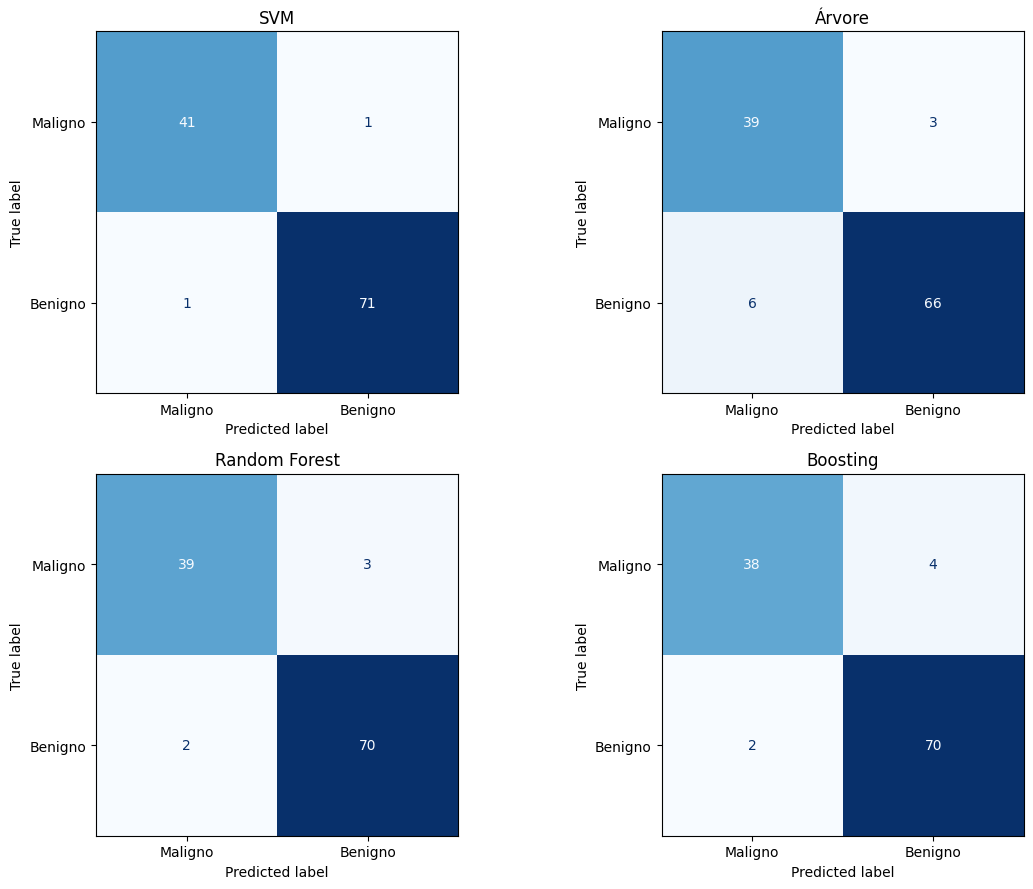

In [32]:
modelos = {
    "SVM": pred_svm_grid,
    "Árvore": pred_arvore_grid,
    "Random Forest": pred_floresta_grid,
    "Boosting": pred_boosting_grid
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (nome, predicao) in zip(axes.ravel(), modelos.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicao,
        ax=ax,
        cmap="Blues",
        colorbar=False,
        display_labels=["Maligno", "Benigno"]
    )

    ax.set_title(nome)

plt.tight_layout()
plt.show()

14. Validaçao cruzada

In [33]:
# Modelos otimizados pelo GridSearchCV

modelos_cv = {

    "SVM": grid_svm.best_estimator_,

    "Árvore de Decisão": grid_arvore.best_estimator_,

    "Random Forest": grid_floresta.best_estimator_,

    "Gradient Boosting": grid_boosting.best_estimator_

}

resultados_cv = {}

# Validação cruzada com 5 divisões

for nome, modelo in modelos_cv.items():

    scores = cross_val_score(

        modelo,

        x_train,

        y_train,

        cv=5,

        scoring="accuracy"

    )

    resultados_cv[nome] = scores.mean()

    print(f"\nModelo: {nome}")

    print("Acurácias:", scores)

    print(f"Média: {scores.mean():.4f}")

    print(f"Porcentagem: {scores.mean() * 100:.2f}%")

# Tabela comparativa

tabela_cv = pd.DataFrame(

    resultados_cv.items(),

    columns=["Modelo", "Validação Cruzada"]

)

display(tabela_cv)


Modelo: SVM
Acurácias: [0.96703297 1.         0.95604396 0.98901099 0.98901099]
Média: 0.9802
Porcentagem: 98.02%

Modelo: Árvore de Decisão
Acurácias: [0.94505495 0.94505495 0.9010989  0.94505495 0.95604396]
Média: 0.9385
Porcentagem: 93.85%

Modelo: Random Forest
Acurácias: [0.96703297 0.98901099 0.93406593 0.94505495 0.96703297]
Média: 0.9604
Porcentagem: 96.04%

Modelo: Gradient Boosting
Acurácias: [0.97802198 0.97802198 0.94505495 0.95604396 0.98901099]
Média: 0.9692
Porcentagem: 96.92%


,Modelo,Validação Cruzada
0,SVM,0.980220
1,Árvore de Decisão,0.938462
2,Random Forest,0.960440
3,Gradient Boosting,0.969231


15. Interpretaçao


1. SVM: apresentou a maior acurácia no teste, com 98,25%, e também a maior média de validação cruzada, com 98,02%.
Árvore de Decisão: obteve 92,11% no teste e 93,85% na validação cruzada, apresentando o menor desempenho entre os modelos.
Random Forest: alcançou 95,61% no teste e 96,04% na validação cruzada.
Gradient Boosting: apresentou 94,74% no teste e 96,92% na validação cruzada.
O SVM apresentou o melhor resultado geral, enquanto o Gradient Boosting também demonstrou um desempenho bastante elevado.
2. Análise dos resultados
SVM
O SVM apresentou a melhor acurácia de teste, com 98,25%, e validação cruzada de 98,02%.
Na matriz de confusão do modelo otimizado, foram registrados:
41 casos malignos classificados corretamente.
71 casos benignos classificados corretamente.
1 caso maligno classificado incorretamente.
1 caso benigno classificado incorretamente.
Isso demonstra que o modelo conseguiu classificar corretamente a grande maioria dos casos.
Árvore de Decisão
A Árvore de Decisão apresentou acurácia de 92,11% no teste e 93,85% na validação cruzada.
Na matriz de confusão, foram registrados 39 casos malignos e 66 benignos classificados corretamente. O modelo apresentou alguns erros de classificação, demonstrando desempenho inferior aos demais.
Random Forest
O Random Forest alcançou 95,61% de acurácia no teste e 96,04% na validação cruzada.
Na matriz de confusão, classificou corretamente 39 casos malignos e 70 benignos. Apresentou poucos erros, demonstrando boa capacidade de classificação.
Gradient Boosting
O Gradient Boosting obteve 94,74% de acurácia no teste e 96,92% na validação cruzada.
Na matriz de confusão, classificou corretamente 38 casos malignos e 70 benignos. Apesar de apresentar uma acurácia de teste um pouco menor que o Random Forest, obteve uma boa média na validação cruzada.
3. Conclusão geral
Com base nos resultados, o SVM foi o modelo com melhor desempenho na classificação do conjunto Breast Cancer, alcançando 98,25% de acurácia no teste e 98,02% na validação cruzada.
O Gradient Boosting também apresentou resultados positivos, com 96,92% de validação cruzada, seguido pelo Random Forest, com 96,04%.
A Árvore de Decisão apresentou o menor desempenho entre os quatro modelos avaliados.
De maneira geral, os resultados demonstram que os modelos conseguiram identificar os padrões presentes nos dados com alta precisão, principalmente o SVM, que apresentou o melhor equilíbrio entre acurácia de teste e validação cruzada.

heart-Dataset

1. Importando as bibliotecas

In [34]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

2. Baixar e carregar o dataset

In [35]:
path = kagglehub.dataset_download(
    "mfarhaannazirkhan/heart-dataset"
)

import os

arquivo = os.path.join(
    path,
    "cleaned_merged_heart_dataset.csv"
)

df = pd.read_csv(arquivo)

print(df.head())
print(df.columns.tolist())

Using Colab cache for faster access to the 'heart-dataset' dataset.
   age  sex  cp  trestbps  chol  fbs  restecg  thalachh  exang  oldpeak  \
0   63    1   3       145   233    1        0       150      0      2.3   
1   37    1   2       130   250    0        1       187      0      3.5   
2   41    0   1       130   204    0        0       172      0      1.4   
3   56    1   1       120   236    0        1       178      0      0.8   
4   57    0   0       120   354    0        1       163      1      0.6   

   slope  ca  thal  target  
0      0   0     1       1  
1      0   0     2       1  
2      2   0     2       1  
3      2   0     2       1  
4      2   0     2       1  
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


3. Preparar os dados

In [36]:
possiveis_alvos = [
    "HeartDisease",
    "heart_disease",
    "target",
    "Heart Disease",
    "output"
]

alvo = next(
    (col for col in possiveis_alvos if col in df.columns),
    None
)

print("Coluna alvo:", alvo)

Coluna alvo: target


4. Dividir treino e teste

In [37]:
x = df.drop(columns=[alvo])
y = df[alvo]

x = pd.get_dummies(x, drop_first=True)
x = x.fillna(x.median())

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

5. Arvore de decisão com GridSearch

In [38]:
arvore = DecisionTreeClassifier(random_state=42)
arvore.fit(x_train, y_train)

pred_arvore = arvore.predict(x_test)

grid_arvore = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        "max_depth": [3, 5, 10, None],
        "min_samples_split": [2, 5, 10],
        "criterion": ["gini", "entropy"]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_arvore.fit(x_train, y_train)
pred_arvore_grid = grid_arvore.predict(x_test)

print("Acurácia da Árvore:", accuracy_score(y_test, pred_arvore))
print("Acurácia com GridSearch:", accuracy_score(y_test, pred_arvore_grid))
print("Melhores parâmetros:", grid_arvore.best_params_)
print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_arvore_grid))

Acurácia da Árvore: 0.9761904761904762
Acurácia com GridSearch: 0.9841269841269841
Melhores parâmetros: {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 2}
Matriz de confusão:
[[177   5]
 [  1 195]]


6. Floresta aleatoria com GridSearch

In [39]:
floresta = RandomForestClassifier(random_state=42)
floresta.fit(x_train, y_train)

pred_floresta = floresta.predict(x_test)

grid_floresta = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_floresta.fit(x_train, y_train)
pred_floresta_grid = grid_floresta.predict(x_test)

print("Acurácia da Floresta:", accuracy_score(y_test, pred_floresta))
print("Acurácia com GridSearch:", accuracy_score(y_test, pred_floresta_grid))
print("Melhores parâmetros:", grid_floresta.best_params_)
print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_floresta_grid))

Acurácia da Floresta: 0.9788359788359788
Acurácia com GridSearch: 0.9735449735449735
Melhores parâmetros: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Matriz de confusão:
[[175   7]
 [  3 193]]


7. Gradient boosting com GridSearch

In [40]:
boosting = GradientBoostingClassifier(random_state=42)
boosting.fit(x_train, y_train)

pred_boosting = boosting.predict(x_test)

grid_boosting = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    {
        "n_estimators": [50, 100, 150],
        "learning_rate": [0.01, 0.1, 0.2],
        "max_depth": [2, 3, 5]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_boosting.fit(x_train, y_train)
pred_boosting_grid = grid_boosting.predict(x_test)

print("Acurácia do Boosting:", accuracy_score(y_test, pred_boosting))
print("Acurácia com GridSearch:", accuracy_score(y_test, pred_boosting_grid))
print("Melhores parâmetros:", grid_boosting.best_params_)
print("Matriz de confusão:")
print(confusion_matrix(y_test, pred_boosting_grid))

Acurácia do Boosting: 0.9338624338624338
Acurácia com GridSearch: 0.9761904761904762
Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150}
Matriz de confusão:
[[175   7]
 [  2 194]]


8. comparar os tres modelos

In [41]:
resultados = pd.DataFrame({
    "Modelo": [
        "Árvore de Decisão",
        "Árvore + GridSearch",
        "Random Forest",
        "Random Forest + GridSearch",
        "Boosting",
        "Boosting + GridSearch"
    ],
    "Acurácia": [
        accuracy_score(y_test, pred_arvore),
        accuracy_score(y_test, pred_arvore_grid),
        accuracy_score(y_test, pred_floresta),
        accuracy_score(y_test, pred_floresta_grid),
        accuracy_score(y_test, pred_boosting),
        accuracy_score(y_test, pred_boosting_grid)
    ]
})

display(resultados.sort_values("Acurácia", ascending=False))

,Modelo,Acurácia
1,Árvore + GridSearch,0.984127
2,Random Forest,0.978836
0,Árvore de Decisão,0.976190
5,Boosting + GridSearch,0.976190
3,Random Forest + GridSearch,0.973545
4,Boosting,0.933862


9. Validaçao cruzada

In [42]:
# Modelos otimizados

modelos_cv = {

    "Árvore de Decisão": grid_arvore.best_estimator_,

    "Random Forest": grid_floresta.best_estimator_,

    "Gradient Boosting": grid_boosting.best_estimator_

}

resultados_cv = {}

# Validação cruzada com 5 divisões

for nome, modelo in modelos_cv.items():

    scores = cross_val_score(

        modelo,

        x_train,

        y_train,

        cv=5,

        scoring="accuracy"

    )

    resultados_cv[nome] = scores.mean()

    print(f"\nModelo: {nome}")

    print("Acurácias:", scores)

    print(f"Média: {scores.mean():.4f}")

    print(f"Porcentagem: {scores.mean() * 100:.2f}%")

# Comparação dos resultados

tabela_cv = pd.DataFrame(

    resultados_cv.items(),

    columns=["Modelo", "Validação Cruzada"]

)

display(tabela_cv)


Modelo: Árvore de Decisão
Acurácias: [0.95364238 0.95033113 0.94370861 0.94701987 0.9602649 ]
Média: 0.9510
Porcentagem: 95.10%

Modelo: Random Forest
Acurácias: [0.98013245 0.9602649  0.95033113 0.9602649  0.96688742]
Média: 0.9636
Porcentagem: 96.36%

Modelo: Gradient Boosting
Acurácias: [0.96357616 0.95364238 0.95033113 0.95364238 0.97019868]
Média: 0.9583
Porcentagem: 95.83%


,Modelo,Validação Cruzada
0,Árvore de Decisão,0.950993
1,Random Forest,0.963576
2,Gradient Boosting,0.958278


10. Interpretaçao

1. Árvore de Decisão: apresentou a maior acurácia no teste, com 98,41%, e 95,10% na validação cruzada.
Random Forest: obteve 97,35% no teste e apresentou a maior média de validação cruzada, com 96,36%.
Gradient Boosting: alcançou 97,62% no teste e 95,83% na validação cruzada.
A Árvore de Decisão teve o melhor resultado no conjunto de teste, enquanto o Random Forest apresentou o melhor desempenho médio na validação cruzada.
2. Análise dos resultados
Árvore de Decisão
A Árvore de Decisão apresentou a maior acurácia no conjunto de teste, com 98,41%.
Sua matriz de confusão apresentou:
177 classificações corretas da classe 0.
195 classificações corretas da classe 1.
5 erros de classificação da classe 0.
1 erro de classificação da classe 1.
O resultado demonstra uma excelente capacidade de classificação nesse conjunto de teste.
Random Forest
O Random Forest alcançou 97,35% de acurácia no teste e 96,36% na validação cruzada.
Na matriz de confusão, apresentou:
175 classificações corretas da classe 0.
193 classificações corretas da classe 1.
7 erros da classe 0.
3 erros da classe 1.
O modelo demonstrou resultados consistentes entre o teste e a validação cruzada.
Gradient Boosting
O Gradient Boosting obteve 97,62% de acurácia no teste e 95,83% na validação cruzada.
Na matriz de confusão, apresentou:
175 classificações corretas da classe 0.
194 classificações corretas da classe 1.
7 erros da classe 0.
2 erros da classe 1.
O modelo também apresentou um bom desempenho, com poucos erros de classificação.
3. Conclusão geral
Com base nos resultados, os três modelos apresentaram altas taxas de acurácia na classificação do Heart Dataset.
A Árvore de Decisão obteve o melhor resultado no conjunto de teste, alcançando 98,41%. Entretanto, o Random Forest apresentou a maior média de validação cruzada, com 96,36%, demonstrando maior consistência entre as diferentes divisões dos dados de treinamento.
O Gradient Boosting também apresentou um desempenho elevado, com 97,62% de acurácia no teste.
De maneira geral, a Árvore de Decisão foi o modelo com melhor resultado no teste, enquanto o Random Forest apresentou o melhor resultado na validação cruzada.

Student Stress Factors

1. Importando as bibliotecas

In [43]:
import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import cross_val_score

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

2. Baixar e carregar o dataset

In [44]:
path = kagglehub.dataset_download(
    "rxnach/student-stress-factors-a-comprehensive-analysis"
) # essa linha faz o dowload do dataset

print("Dataset baixado em:", path)

arquivos = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
) # localiza arquivos csv

print("\nArquivos encontrados:")
for arquivo in arquivos:
    print(arquivo)

if not arquivos:
    raise FileNotFoundError("Nenhum arquivo CSV encontrado.")

df = None

for arquivo in arquivos:
    teste = pd.read_csv(arquivo)

    teste.columns = (
        teste.columns.astype(str)
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

    if "stress_level" in teste.columns:
        df = teste
        arquivo_escolhido = arquivo
        break

if df is None:
    raise ValueError("Coluna stress_level não encontrada.")

print("\nDataset carregado com sucesso!")
print("Arquivo:", arquivo_escolhido)
print("Dimensões:", df.shape)

display(df.head())


Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.
Dataset baixado em: /kaggle/input/student-stress-factors-a-comprehensive-analysis

Arquivos encontrados:
/kaggle/input/student-stress-factors-a-comprehensive-analysis/StressLevelDataset.csv

Dataset carregado com sucesso!
Arquivo: /kaggle/input/student-stress-factors-a-comprehensive-analysis/StressLevelDataset.csv
Dimensões: (1100, 21)


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


3. Preparação dos dados

In [45]:
# Verifica valores ausentes
print("Valores ausentes:")
print(df.isnull().sum())


x = df.drop(columns=["stress_level"])
y = df["stress_level"]

x = pd.get_dummies(x, drop_first=False) # Transformar variáveis categóricas em numéricas, se existirem
# Dividir dados em treino e teste
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", x_train.shape)
print("Teste:", x_test.shape)

print("\nDistribuição das classes:")
print(y.value_counts().sort_index())


Valores ausentes:
anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64
Treinamento: (880, 20)
Teste: (220, 20)

Distribuição das classes:
stress_level
0    373
1    358
2    369
Name: count, dtype: int64


4. Arvore de Decisão

Acurácia da Árvore de Decisão: 0.8545454545454545

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.86      0.80      0.83        74
           1       0.82      0.90      0.86        72
           2       0.89      0.86      0.88        74

    accuracy                           0.85       220
   macro avg       0.86      0.85      0.85       220
weighted avg       0.86      0.85      0.85       220



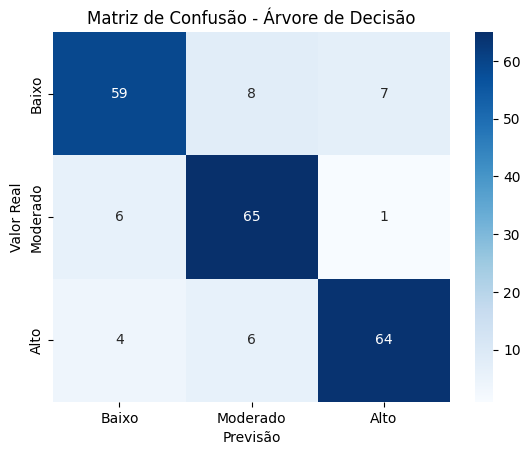

In [46]:
# essa linha de baixo cria o modelo
arvore = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

arvore.fit(x_train, y_train)

y_pred_arvore = arvore.predict(x_test)

acc_arvore = accuracy_score(y_test, y_pred_arvore)

print("Acurácia da Árvore de Decisão:", acc_arvore)

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_arvore))

cm_arvore = confusion_matrix(
    y_test, y_pred_arvore, labels=[0, 1, 2]
)

sns.heatmap(
    cm_arvore,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Baixo", "Moderado", "Alto"],
    yticklabels=["Baixo", "Moderado", "Alto"]
)

plt.title("Matriz de Confusão - Árvore de Decisão")
plt.xlabel("Previsão")
plt.ylabel("Valor Real")
plt.show()


5.Floresta aleatória

Acurácia da Floresta Aleatória: 0.8909090909090909

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.93      0.84      0.88        74
           1       0.89      0.93      0.91        72
           2       0.86      0.91      0.88        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220



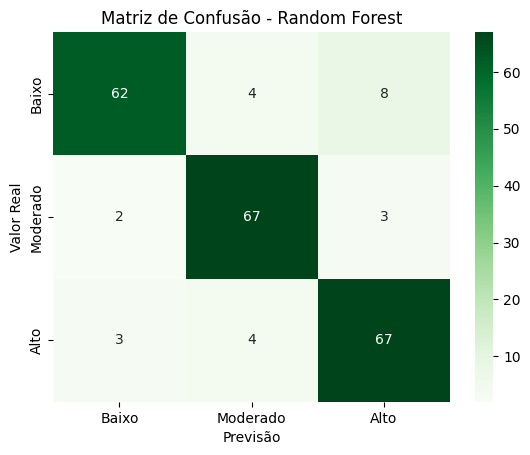

In [47]:
# essa linha de baixo cria o modelo
floresta = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

floresta.fit(x_train, y_train)

y_pred_floresta = floresta.predict(x_test)

acc_floresta = accuracy_score(y_test, y_pred_floresta)

print("Acurácia da Floresta Aleatória:", acc_floresta)

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_floresta))

cm_floresta = confusion_matrix(
    y_test, y_pred_floresta, labels=[0, 1, 2]
)

sns.heatmap(
    cm_floresta,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Baixo", "Moderado", "Alto"],
    yticklabels=["Baixo", "Moderado", "Alto"]
)

plt.title("Matriz de Confusão - Random Forest")
plt.xlabel("Previsão")
plt.ylabel("Valor Real")
plt.show()


6. Gradient Boosting

Acurácia do Boosting: 0.8727272727272727

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85        74
           1       0.87      0.93      0.90        72
           2       0.86      0.86      0.86        74

    accuracy                           0.87       220
   macro avg       0.87      0.87      0.87       220
weighted avg       0.87      0.87      0.87       220



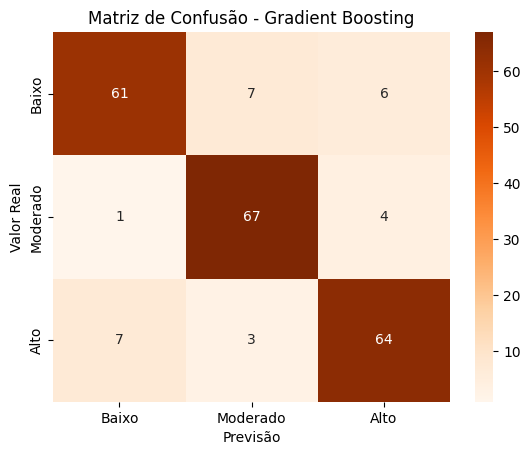

In [48]:
# essa linha de baixo cria o modelo
boosting = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

boosting.fit(x_train, y_train)

y_pred_boosting = boosting.predict(x_test)

acc_boosting = accuracy_score(y_test, y_pred_boosting)

print("Acurácia do Boosting:", acc_boosting)

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_boosting))

cm_boosting = confusion_matrix(
    y_test, y_pred_boosting, labels=[0, 1, 2]
)

sns.heatmap(
    cm_boosting,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Baixo", "Moderado", "Alto"],
    yticklabels=["Baixo", "Moderado", "Alto"]
)

plt.title("Matriz de Confusão - Gradient Boosting")
plt.xlabel("Previsão")
plt.ylabel("Valor Real")
plt.show()


7. Otimização dos modelos com GridSearchCV

In [49]:
# esse bloco e um dicionario com os modelos e seus parametros
modelos = {
    "Árvore de Decisão": {
        "pipeline": arvore,
        "parametros": {
            "modelo__max_depth": [3, 5, 10, None],
            "modelo__min_samples_split": [2, 5, 10],
            "modelo__criterion": ["gini", "entropy"]
        }
    },

    "Random Forest": {
        "pipeline": floresta,
        "parametros": {
            "modelo__n_estimators": [100, 200],
            "modelo__max_depth": [5, 10, None],
            "modelo__min_samples_split": [2, 5],
            "modelo__criterion": ["gini", "entropy"]
        }
    },

    "Gradient Boosting": {
        "pipeline": boosting,
        "parametros": {
            "modelo__n_estimators": [50, 100, 200],
            "modelo__learning_rate": [0.01, 0.1, 0.2],
            "modelo__max_depth": [2, 3, 5]
        }
    }
}
# Aqui em baixo armazenar os resultados
resultados_grid = {}
melhores_modelos = {}

for nome, configuracao in modelos.items():

    print("\nOtimizando:", nome)

    grid = GridSearchCV(
        estimator=configuracao["pipeline"],
        param_grid=configuracao["parametros"],
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1
    )

    grid.fit(x_train, y_train)

    melhores_modelos[nome] = grid.best_estimator_

    y_pred = grid.predict(x_test)

    resultados_grid[nome] = {
        "Acurácia": accuracy_score(y_test, y_pred),
        "Melhores parâmetros": grid.best_params_,
        "Matriz de confusão": confusion_matrix(
            y_test, y_pred, labels=[0, 1, 2]
        ),
        "Previsões": y_pred
    }

    print("Melhores parâmetros:", grid.best_params_)
    print("Melhor acurácia na validação:", grid.best_score_)
    print("Acurácia no teste:", resultados_grid[nome]["Acurácia"])



Otimizando: Árvore de Decisão
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Melhores parâmetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 10, 'modelo__min_samples_split': 10}
Melhor acurácia na validação: 0.8920454545454545
Acurácia no teste: 0.8590909090909091

Otimizando: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Melhores parâmetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 100}
Melhor acurácia na validação: 0.884090909090909
Acurácia no teste: 0.8818181818181818

Otimizando: Gradient Boosting
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Melhores parâmetros: {'modelo__learning_rate': 0.01, 'modelo__max_depth': 5, 'modelo__n_estimators': 200}
Melhor acurácia na validação: 0.8988636363636363
Acurácia no teste: 0.8636363636363636


8. Comparação das acurácias

              Modelo  Acurácia Original  Acurácia GridSearch
0  Árvore de Decisão           0.854545             0.859091
1      Random Forest           0.890909             0.881818
2  Gradient Boosting           0.872727             0.863636


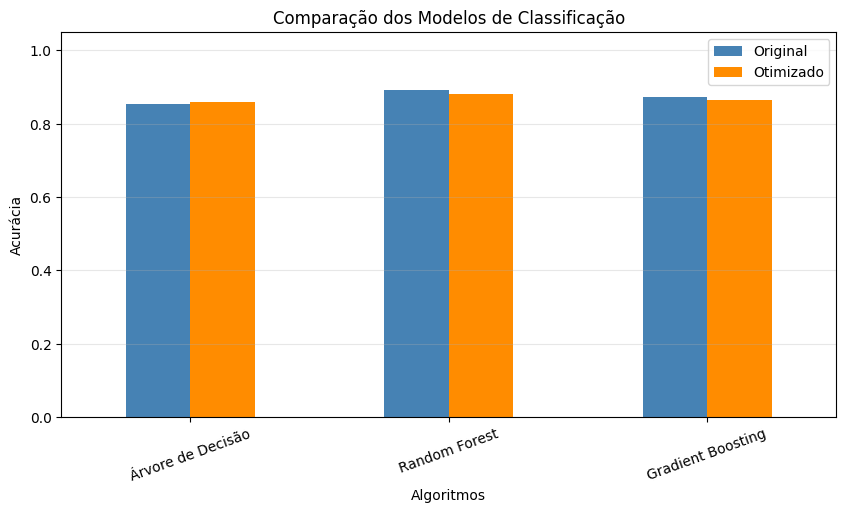

In [50]:
# esse bloco criar tabela comparativa
comparacao = pd.DataFrame({
    "Modelo": [
        "Árvore de Decisão",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Acurácia Original": [
        acc_arvore,
        acc_floresta,
        acc_boosting
    ],
    "Acurácia GridSearch": [
        resultados_grid["Árvore de Decisão"]["Acurácia"],
        resultados_grid["Random Forest"]["Acurácia"],
        resultados_grid["Gradient Boosting"]["Acurácia"]
    ]
})

print(comparacao)
# aqui em em baixo e o grafico comparativo
comparacao_plot = comparacao.set_index("Modelo")

comparacao_plot.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Comparação dos Modelos de Classificação")
plt.ylabel("Acurácia")
plt.xlabel("Algoritmos")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(["Original", "Otimizado"])
plt.grid(axis="y", alpha=0.3)
plt.show()


9. Matriz de confusão dos modelos otimizados

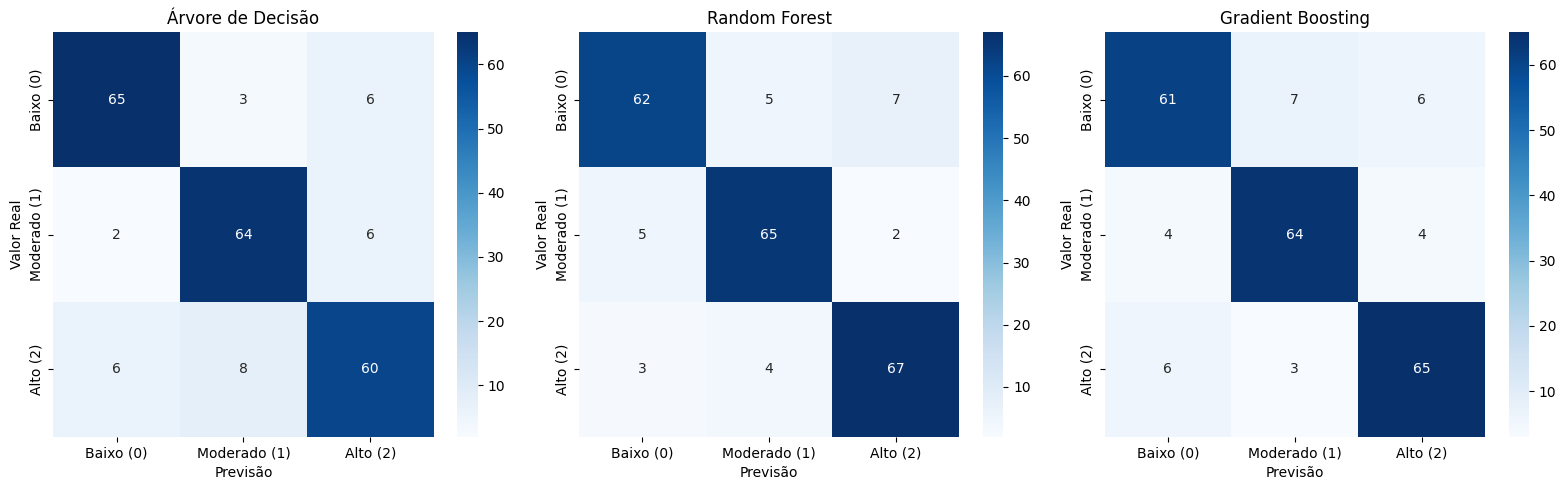

In [51]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nome, resultado) in zip(
    axes, resultados_grid.items()
):

    sns.heatmap(
        resultado["Matriz de confusão"],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Baixo (0)", "Moderado (1)", "Alto (2)"],
        yticklabels=["Baixo (0)", "Moderado (1)", "Alto (2)"],
        ax=ax
    )

    ax.set_title(nome)
    ax.set_xlabel("Previsão")
    ax.set_ylabel("Valor Real")

plt.tight_layout()
plt.show()



10. Validaçao cruzada

In [52]:

# Validação cruzada dos melhores modelos
for nome, modelo in melhores_modelos.items():

    resultados_cv = cross_val_score(
        modelo,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    print("\nModelo:", nome)
    print("Resultados:", resultados_cv)
    print("Média:", resultados_cv.mean())
    print("Desvio padrão:", resultados_cv.std())


Modelo: Árvore de Decisão
Resultados: [0.89204545 0.88636364 0.90340909 0.88068182 0.89772727]
Média: 0.8920454545454545
Desvio padrão: 0.008035304331665305

Modelo: Random Forest
Resultados: [0.90340909 0.89204545 0.91477273 0.84659091 0.86363636]
Média: 0.884090909090909
Desvio padrão: 0.025308019831045574

Modelo: Gradient Boosting
Resultados: [0.90340909 0.90340909 0.92613636 0.875      0.88636364]
Média: 0.8988636363636363
Desvio padrão: 0.017383021069066317


11. Interpretaçao

1. Comparação das acurácias
Na validação cruzada, o Gradient Boosting apresentou o melhor resultado, com média de 89,89%. Em seguida, ficou a Árvore de Decisão, com 89,20%, e o Random Forest, com 88,41%.
Já na avaliação com os dados de teste, o Random Forest apresentou o melhor resultado, com 88,18%, seguido pelo Gradient Boosting, com 86,36%, e pela Árvore de Decisão, com 85,91%.
2. Análise dos resultados
O Gradient Boosting apresentou o melhor desempenho médio na validação cruzada, demonstrando boa capacidade de classificação. A Árvore de Decisão teve o menor desvio padrão (0,80%), indicando maior estabilidade entre as cinco divisões. O Random Forest apresentou maior variação nos resultados, com desvio padrão de 2,53%.
Na matriz de confusão do Random Forest, o modelo acertou 194 das 220 previsões. Ele teve bons resultados nas três categorias: estresse baixo, moderado e alto. O melhor resultado foi na identificação do estresse alto, com 67 acertos de 74 casos.
3. Conclusão geral
Conclui-se que os três modelos apresentaram bons resultados na classificação dos níveis de estresse dos estudantes. O Gradient Boosting obteve a maior média na validação cruzada, enquanto o Random Forest alcançou a maior acurácia no conjunto de teste. A Árvore de Decisão, por sua vez, apresentou maior estabilidade entre as divisões da validação cruzada.
Portanto, considerando os resultados do conjunto de teste, o Random Forest foi o melhor modelo, com 88,18% de acurácia.

Fish Morph

1. Importando as bibliotecas

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

2. Baixa o dataset pelo kagglehub

In [4]:
# esse bloco carrega o dataset
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

print("Caminho do dataset:", path)

print("Arquivos disponíveis:")
print(os.listdir(path))

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.
Caminho do dataset: /kaggle/input/fishmorph-dataset
Arquivos disponíveis:
['FISHMORPH_Order_Dataset.csv', 'FISHMORPH_Family_Dataset.csv']


3. Localizar e carregar o arquivo CSV

In [5]:
arquivos_csv = [] # essa linha cria uma lista vazia para armazenar os CSV
# o codigo abaixo percorre todas as pastas do dataset
for raiz, pastas, arquivos in os.walk(path):
    for arquivo in arquivos:
        if arquivo.endswith(".csv"):
            arquivos_csv.append(os.path.join(raiz, arquivo))

print(arquivos_csv)

df = pd.read_csv(arquivos_csv[0])

print("Dataset carregado!")
print("Dimensões:", df.shape)

display(df.head())

['/kaggle/input/fishmorph-dataset/FISHMORPH_Order_Dataset.csv', '/kaggle/input/fishmorph-dataset/FISHMORPH_Family_Dataset.csv']
Dataset carregado!
Dimensões: (8342, 11)


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Order
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cypriniformes
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Perciformes
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cypriniformes
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cypriniformes
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cypriniformes


4. Analisar as colunas

In [6]:
print("colunas:")
print(df.columns.tolist()) # mostra os nomes das colunas

print("\ninformaçoes:")
df.info() # mostra as informaçoes do dataframe

colunas:
['MBl', 'BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv', 'PFs', 'CPt', 'Order']

informaçoes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Order   8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB


5. Preparar os dados

In [7]:
# separaçao das variaveis x e y
x = df.drop(columns=["Order"])
y = df["Order"]

contagem = y.value_counts() # essa linha mostra quantas vezes cada familia aparece

familias_validas = contagem[contagem >= 2].index # identifica as familias que possuem pelo menos 2 registros

x = x[y.isin(familias_validas)]
y = y[y.isin(familias_validas)]

print("Quantidade de registros:", len(x))
print("Quantidade de famílias:", y.nunique())

print("\nDistribuição das famílias:")
print(y.value_counts())

Quantidade de registros: 8340
Quantidade de famílias: 30

Distribuição das famílias:
Order
Cypriniformes         1933
Perciformes           1826
Siluriformes          1800
Characiformes         1281
Cyprinodontiformes     554
Osteoglossiformes      156
Clupeiformes           104
Gymnotiformes          101
Salmoniformes           92
Atheriniformes          71
Scorpaeniformes         70
Osmeriformes            69
Synbranchiformes        48
Beloniformes            33
Tetraodontiformes       31
Pleuronectiformes       29
Acipenseriformes        23
Mugiliformes            18
Anguilliformes          16
Syngnathiformes         16
Gasterosteiformes       13
Gonorynchiformes        10
Esociformes             10
Polypteriformes          9
Percopsiformes           6
Lepisosteiformes         6
Elopiformes              5
Batrachoidiformes        4
Gobiesociformes          3
Gadiformes               3
Name: count, dtype: int64


6. dividir treino e teste

In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treino:", x_train.shape)
print("Teste:", x_test.shape)

Treino: (6672, 10)
Teste: (1668, 10)


7. SVM com GridSearchCV

In [9]:
# esse bloco cria um Pipeline com as etapas de preparação dos dados e o modelo SVM
svm = Pipeline([ # Preenche valores ausentes (NaN) utilizando a mediana de cada coluna
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()), # Padroniza os dados para que tenham media 0 e desvio padrão 1
    ("modelo", SVC())
])
# Define os hiperparametros que serao testados pelo GridSearchCV
parametros = {
    "modelo__kernel": ["linear", "rbf", "sigmoid"],
    "modelo__C": [0.1, 1, 10],
    "modelo__gamma": ["scale", 0.01, 0.1]
}

grid = GridSearchCV(
    svm,
    parametros,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid.fit(x_train, y_train)

y_pred_svm = grid.predict(x_test)

print("Melhores parâmetros:", grid.best_params_)
print("Acurácia validação:", grid.best_score_)
print("Acurácia teste:", accuracy_score(y_test, y_pred_svm))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nRelatório:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

Fitting 3 folds for each of 27 candidates, totalling 81 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(


Melhores parâmetros: {'modelo__C': 10, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
Acurácia validação: 0.7810251798561151
Acurácia teste: 0.8123501199040767

Matriz de confusão:
[[  3   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   1   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   3   0   0   0]
 [  0   0  11   0   0   0   0   0   2   0   0   0   0   0   0   0   0   0
    1   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   7   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 203   2  37   6   0   0   0   0   0   0   0   0   0
    0   0   2   0   0   0   1   0   5   0   0   0]
 [  0   0   0   0   0   8   7   3   0   0   0   0   0   0   0   0

8. Arvore de decisão

In [10]:
# esse bloco cria um Pipeline com as etapas de tratamento dos dados
# e o modelo de arvore de decisao
arvore = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

arvore.fit(x_train, y_train)

y_pred_arvore = arvore.predict(x_test)

print("Acurácia:", accuracy_score(y_test, y_pred_arvore))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_arvore))

print("\nRelatório:")
print(classification_report(y_test, y_pred_arvore, zero_division=0))

Acurácia: 0.6528776978417267

Matriz de confusão:
[[  2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   1   0   0   0]
 [  0   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   1   0   0   0]
 [  0   0   3   0   2   0   0   0   3   0   0   0   0   0   0   0   0   0
    0   0   5   0   0   0   1   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   6   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 158   4  63   6   1   0   0   0   0   0   0   0   1
    0   1   9   0   0   0   3   0   9   0   0   1]
 [  0   0   0   0   0   9   3   4   0   0   0   0   1   0   0   0   0   0
    0   1   2   0   0   0   1   0   0   0   0   0]
 [  0   0   0   0   0  51   4 241   5   0   0   0   0   0   0   0   0   2
 

9. Random Forest

In [11]:
# esse bloco cria um Pipeline com o tratamento dos dados e o modelo Random Forest
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)

print("Acurácia:", accuracy_score(y_test, y_pred_rf))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRelatório:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Acurácia: 0.7793764988009593

Matriz de confusão:
[[  2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   1   0   0   0   0   0   0   1   0   0   0]
 [  0   2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   1   0   0]
 [  0   0   8   0   0   0   0   0   1   0   0   0   0   0   0   0   0   0
    0   0   5   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   6   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 202   1  38   3   0   0   0   0   0   0   0   0   0
    0   0   3   0   0   0   2   0   7   0   0   0]
 [  0   0   0   0   0  12   1   3   1   0   0   0   0   0   0   0   0   0
    0   0   3   0   0   0   0   0   1   0   0   0]
 [  0   0   0   0   0  34   0 291   2   0   0   0   0   0   0   0   0   0
 

10. Gradient Boosting

In [12]:
# esse bloco cria um Pipeline com o tratamento dos dados e o modelo Gradient Boosting
boosting = Pipeline([
    # Preenche os valores ausentes (NaN) utilizando a mediana
    # de cada coluna numerica
    ("imputer", SimpleImputer(strategy="median")),
    ("modelo", GradientBoostingClassifier(
        n_estimators=30, # essa linha define a quantidade de arvores que serao construidas
        learning_rate=0.1, # essa linha define a taxa de aprendizado do modelo e controla a contribuiçao de cada arvore no resultado final
        max_depth=2, # essa linha define a profundidade maxima de cada arvore e limita a complexidade das arvores utilizadas
        random_state=42 # essa linha define uma semente para garantir a reproduçao dos resultados
    ))
])

boosting.fit(x_train, y_train)

y_pred_boost = boosting.predict(x_test)

print("Acurácia:", accuracy_score(y_test, y_pred_boost))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_boost))

print("\nRelatório:")
print(classification_report(y_test, y_pred_boost, zero_division=0))

Acurácia: 0.7122302158273381

Matriz de confusão:
[[  2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   1   0   0   0]
 [  0   3   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   6   0   1   0   0   0   2   0   0   0   0   0   0   0   0   0
    2   0   3   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   5   0   0   0   0   0   1   0   0   0   0   0   0   0
    0   0   1   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 181   1  53   6   0   0   0   0   0   0   0   0   0
    0   0   9   0   0   0   0   0   3   0   0   3]
 [  0   0   1   0   0  11   0   6   0   0   0   0   0   0   0   0   0   0
    0   0   2   0   0   0   1   0   0   0   0   0]
 [  0   0   0   0   0  41   0 273   4   1   0   0   0   0   0   0   0   0
 

11. Comparação dos resultados

In [13]:
# esse bloco cria um DataFrame para armazenar os resultados
# da avaliação dos quatro modelos de Machine Learning
resultados = pd.DataFrame({
    "Modelo": [  # Define os nomes dos modelos que serão comparados
        "SVM",
        "Árvore de Decisão",
        "Random Forest",
        "Boosting"
    ],
# Calcula a acuracia de cada modelo
# Compara as previsoes realizadas com os valores reais (y_test)
    "Acurácia": [
        accuracy_score(y_test, y_pred_svm), # Acuracia do SVM
        accuracy_score(y_test, y_pred_arvore), # Acuracia da arvore de decisao
        accuracy_score(y_test, y_pred_rf), # Acuracia do random forest
        accuracy_score(y_test, y_pred_boost) # Acuracia do Gradient Boosting
    ]
})

resultados = resultados.sort_values(
    by="Acurácia",
    ascending=False
)

display(resultados)

print("Melhor modelo:")
print(resultados.iloc[0])

,Modelo,Acurácia
0,SVM,0.812350
2,Random Forest,0.779376
3,Boosting,0.712230
1,Árvore de Decisão,0.652878


Melhor modelo:
Modelo          SVM
Acurácia    0.81235
Name: 0, dtype: object


12. Grafico comparativo

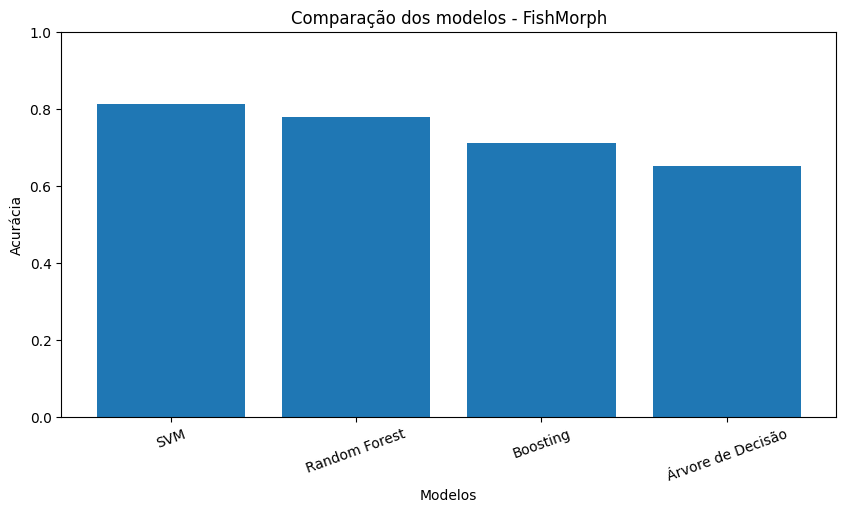

In [14]:
# Define o tamanho da figura do gráfico
# 10 representa a largura e 5 representa a altura
plt.figure(figsize=(10, 5))
# Cria um grafico de barras utilizando os resultados dos modelos
plt.bar(
    resultados["Modelo"],
    resultados["Acurácia"]
)

plt.title("Comparação dos modelos - FishMorph")
plt.xlabel("Modelos")
plt.ylabel("Acurácia")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.show()

13. Matriz de confusão

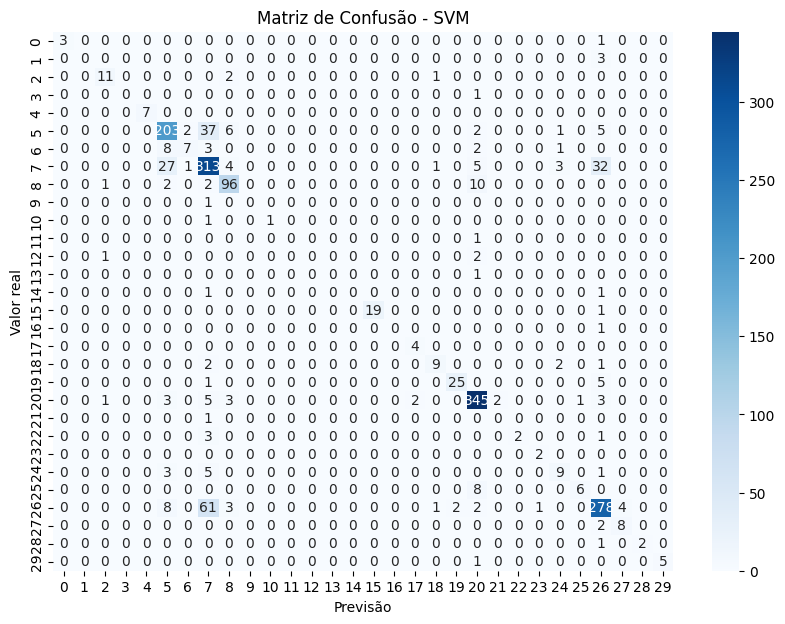

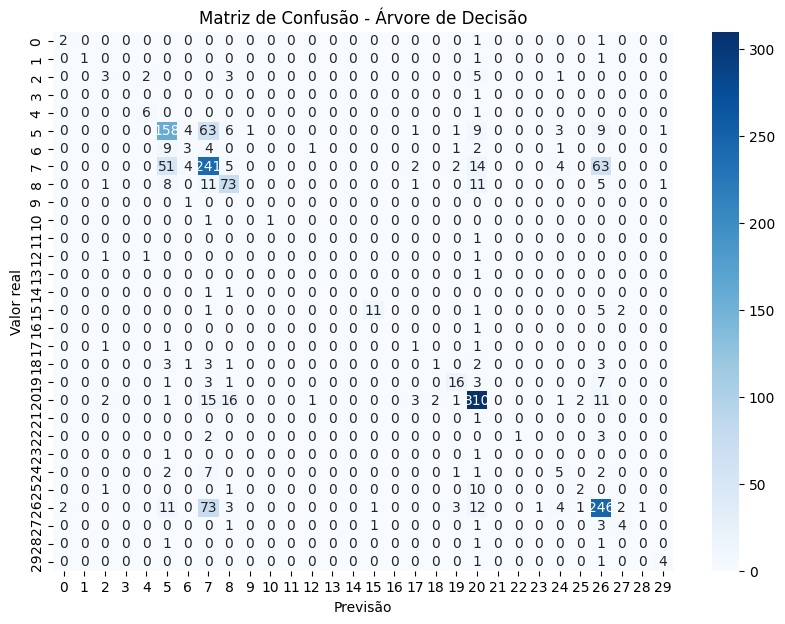

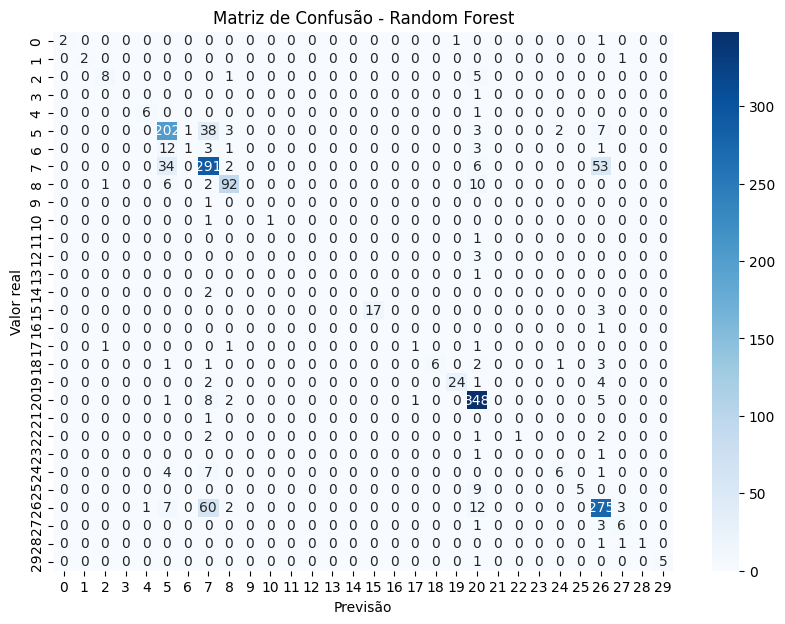

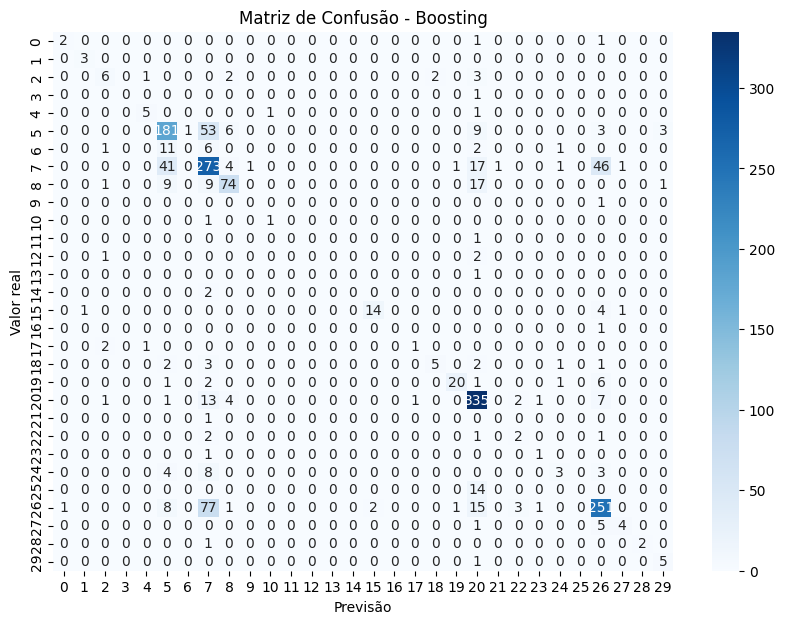

In [15]:
#  esse bloco cria um dicionario contendo os nomes dos modelos
# e suas respectivas previsoes realizadas no conjunto de teste
modelos = {
    "SVM": y_pred_svm,
    "Árvore de Decisão": y_pred_arvore,
    "Random Forest": y_pred_rf,
    "Boosting": y_pred_boost
}
# Percorre todos os modelos armazenados no dicionario
# nome recebe o nome do modelo
# previsoes recebe as classificaçoes realizadas por esse modelo
for nome, previsoes in modelos.items():

    cm = confusion_matrix(y_test, previsoes)

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Matriz de Confusão - " + nome)
    plt.xlabel("Previsão")
    plt.ylabel("Valor real")
    plt.show()

14. Interpretaçao

1. SVM: apresentou a maior acurácia no conjunto de teste, com 81,24%. Na validação cruzada, obteve 76,02%.
Árvore de Decisão: apresentou o menor desempenho, com 65,29% no teste e 64,91% na validação cruzada.
Random Forest: alcançou 77,94% no teste e 76,03% na validação cruzada, demonstrando resultados consistentes.
Gradient Boosting: obteve 71,22% no teste e 68,30% na validação cruzada.
O SVM apresentou o melhor resultado no teste, enquanto o Random Forest teve a maior média de validação cruzada, com uma diferença muito pequena em relação ao SVM.
2. Análise dos resultados
SVM
O SVM apresentou a melhor acurácia geral no conjunto de teste, de 81,24%. Também obteve bons resultados em algumas famílias, como Perciformes, com F1-score de 0,93, e Siluriformes, com 0,80.
Entretanto, o F1-score macro foi de 0,54, indicando que o desempenho não foi equilibrado entre todas as classes. Algumas famílias com poucos registros tiveram dificuldades de classificação.
Árvore de Decisão
A Árvore de Decisão apresentou a menor acurácia, de 65,29%, e F1-score macro de 0,32.
Isso demonstra dificuldade para classificar corretamente algumas famílias, principalmente aquelas com menor quantidade de registros.
Random Forest
O Random Forest apresentou acurácia de 77,94% e F1-score macro de 0,46.
Teve bons resultados em famílias mais representadas, como Perciformes, com F1-score de 0,90. Sua validação cruzada de 76,03% também indica consistência nos resultados.
Gradient Boosting
O Gradient Boosting alcançou acurácia de 71,22% e F1-score macro de 0,40.
Apresentou desempenho intermediário entre os modelos, mas também demonstrou dificuldades para classificar algumas das famílias menos representadas.
Observação sobre o conjunto de dados
O aviso apresentado pelo Python informa que a classe menos populosa possui apenas 2 registros, enquanto a validação cruzada utiliza 3 divisões (folds).
Isso indica um desequilíbrio entre as classes e pode prejudicar a avaliação das famílias com poucos exemplos. Portanto, os resultados dessas classes devem ser interpretados com cautela.
3. Conclusão geral
Com base nos resultados, o SVM foi o modelo com melhor desempenho no conjunto de teste, alcançando 81,24% de acurácia. O Random Forest também apresentou bons resultados, com 77,94% de acurácia no teste e 76,03% na validação cruzada.
A Árvore de Decisão apresentou o menor desempenho entre os modelos avaliados, enquanto o Gradient Boosting obteve resultados intermediários.
De maneira geral, o SVM foi o modelo mais eficiente na classificação das famílias de peixes nesse experimento. Entretanto, o desequilíbrio entre as classes influenciou os resultados, principalmente nas famílias com poucos registros.

15. Validaçao cruzada

In [18]:
# Modelos que serao avaliados

modelos = {

    "SVM": svm,

    "Arvore de Decisao": arvore,

    "Random Forest": rf,

    "Gradient Boosting": boosting

}

# Dicionario para guardar os resultados

resultados_cv = {}

# Validação cruzada com 3 divisoes

for nome, modelo in modelos.items():

    scores = cross_val_score(

        modelo,

        x_train,

        y_train,

        cv=3,

        scoring="accuracy"

    )

    resultados_cv[nome] = scores.mean()

    print(f"\nModelo: {nome}")

    print("Acurácias:", scores)

    print(f"Média da validação cruzada: {scores.mean():.4f}")

    print(f"Porcentagem: {scores.mean() * 100:.2f}%")

# Tabela comparativa

tabela_cv = pd.DataFrame(

    resultados_cv.items(),

    columns=["Modelo", "Validação Cruzada"]

)

print("\nComparação dos modelos:")

display(tabela_cv)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(



Modelo: SVM
Acurácias: [0.76753597 0.76169065 0.75134892]
Média da validação cruzada: 0.7602
Porcentagem: 76.02%


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(



Modelo: Arvore de Decisao
Acurácias: [0.65872302 0.63938849 0.64928058]
Média da validação cruzada: 0.6491
Porcentagem: 64.91%


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(



Modelo: Random Forest
Acurácias: [0.77158273 0.75584532 0.75359712]
Média da validação cruzada: 0.7603
Porcentagem: 76.03%


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=3.
  warnings.warn(



Modelo: Gradient Boosting
Acurácias: [0.69244604 0.68660072 0.66996403]
Média da validação cruzada: 0.6830
Porcentagem: 68.30%

Comparação dos modelos:


,Modelo,Validação Cruzada
0,SVM,0.760192
1,Arvore de Decisao,0.649131
2,Random Forest,0.760342
3,Gradient Boosting,0.683004


Cartao de Credito Indiano

1. Importando as bibliotecas

In [74]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, KFold
from google.colab import files
import numpy as np

2. Baixando e carregando o dataset

In [ ]:
path = kagglehub.dataset_download("babbaransh12/indian-credit-card")

df = pd.read_csv(os.path.join(path, 'credit_1.csv'))

print('Formato:', df.shape)
print('Colunas:', df.columns.tolist())

display(df.head())

Using Colab cache for faster access to the 'indian-credit-card' dataset.
Formato: (366, 15)
Colunas: ['Card Name', 'Issuer', 'Annual Fee', 'Min Income', 'Credit Limit', 'Cashback %', 'Reward Rate', 'Reward Type', 'Category', 'Forex Fee', 'Lounge Access', 'Joining Bonus', 'Spend Requirement', 'Key Benefits', 'Best For']


,Card Name,Issuer,Annual Fee,Min Income,Credit Limit,Cashback %,Reward Rate,Reward Type,Category,Forex Fee,Lounge Access,Joining Bonus,Spend Requirement,Key Benefits,Best For
0,Infinia Metal,HDFC Bank,"₹12,500",₹3L+/month,8L–20L,~3.3%,5X–10X,Reward Points,Super Premium,~2%,Unlimited Global,Yes,₹4L/qtr,"Luxury perks, concierge",HNI users
1,Diners Club Black,HDFC Bank,"₹10,000",₹1.75L+/month,5L–15L,~3%,5X–10X,Reward Points,Premium,~2%,Unlimited,Yes,₹5L/year,SmartBuy rewards,Frequent travelers
2,Regalia Gold,HDFC Bank,"₹2,500",₹1L+/month,3L–10L,~1–2%,4X–5X,Reward Points,Travel,~2%,12/year,Yes,₹1.5L/qtr,Travel vouchers,Mid-high income
3,Diners Privilege,HDFC Bank,"₹2,500",₹70k+/month,2L–8L,~1–2%,4X,Reward Points,Lifestyle,~2%,8/year,Yes,₹3L/year,Dining offers,Lifestyle users
4,Millennia,HDFC Bank,"₹1,000",₹35k+/month,1L–5L,5%,1–2X,Cashback,Cashback,~3.5%,Limited,Yes,₹1L/year,Online cashback,Students/young


3. Divisao de treino e teste

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print("Formato dos dados de treinamento:", x_train.shape)
print("Formato dos dados de teste:", x_test.shape)

print("Formato dos rótulos de treinamento:", y_train.shape)
print("Formato dos rótulos de teste:", y_test.shape)

print("\nDivisão concluída com sucesso!")

Formato dos dados de treinamento: (292, 510)
Formato dos dados de teste: (74, 510)
Formato dos rótulos de treinamento: (292,)
Formato dos rótulos de teste: (74,)

Divisão concluída com sucesso!


4. Conversao dos atributos

In [ ]:
x = df.drop(columns=['Category', 'Card Name', 'Best For'])

x = pd.get_dummies(x, drop_first=True)

y = df['Category']

print("Conversão concluída!")
print("Formato de x:", x.shape)
print("Formato de y:", y.shape)

Conversão concluída!
Formato de x: (366, 770)
Formato de y: (366,)


5. Criacao e treinamento dos modelos

In [ ]:
x = df.drop(columns=['Category', 'Card Name', 'Best For'])
y = df['Category']

x = pd.get_dummies(x, drop_first=True)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print(x_train.select_dtypes(include=['object']).columns.tolist())

[]


In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

for nome, modelo in modelos.items():
    modelo.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado
SVM: treinado


6. Previsoes nos dados de teste

In [ ]:
previsoes = {nome: modelo.predict(x_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 193         Premium
33             Fuel
15           Travel
310    Professional
57           Travel
           ...     
82          Premium
94           Travel
192         Secured
307    Premium-lite
211    Professional
Name: Category, Length: 74, dtype: object
Árvore de Decisão: ['Premium' 'Fuel' 'Entertainment' 'Premium' 'Travel' 'Digital' 'Travel'
 'UPI' 'Defense' 'Business' '0% Purchase' 'Travel' 'Senior' 'Premium'
 'Premium' 'Senior' 'Co-branded' 'Premium' 'Online' 'UPI' 'Co-branded'
 'Entry' 'Entry' 'Professional' 'Digital' 'Lifestyle' 'Entry' 'Entry'
 'Rewards' 'Premium' 'Professional' 'Travel' 'Travel' 'Fuel' 'Entry'
 'Entertainment' 'Cashback' 'Entry' 'Rewards' 'Digital' 'Entry' 'Travel'
 'Cashback' 'Professional' 'Premium' 'Premium' 'Travel' 'Travel' 'Entry'
 'Super Premium' 'Travel' 'Travel' 'Secured' 'Entry' 'Co-branded'
 'Premium' 'Travel' 'Co-branded' 'Premium' 'Digital' 'Co-branded'
 'Premium' 'Entertainment' 'Co-branded' 'Secured' 'Lifestyle' 'Entry'
 'Co

7. Avaliação e comparação

In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 39.19%
                  precision    recall  f1-score   support

     0% Purchase       0.00      0.00      0.00         0
Balance Transfer       0.00      0.00      0.00         1
        Business       1.00      1.00      1.00         1
        Cashback       0.00      0.00      0.00         2
      Co-branded       0.29      0.20      0.24        10
         Defense       0.00      0.00      0.00         0
         Digital       0.00      0.00      0.00         3
 Digital Premium       0.00      0.00      0.00         1
   Entertainment       0.00      0.00      0.00         1
           Entry       0.50      1.00      0.67         5
            Fuel       1.00      1.00      1.00         2
       Lifestyle       0.50      0.17      0.25         6
          Online       0.00      0.00      0.00         0
         Premium       0.33      0.44      0.38         9
    Premium-lite       0.00      0.00      0.00         1
    Professional       0.25      

,Modelo,Acurácia
2,Gradient Boosting,0.540541
1,Random Forest,0.500000
3,SVM,0.486486
0,Árvore de Decisão,0.391892


8. Visualizaçao das previsoes

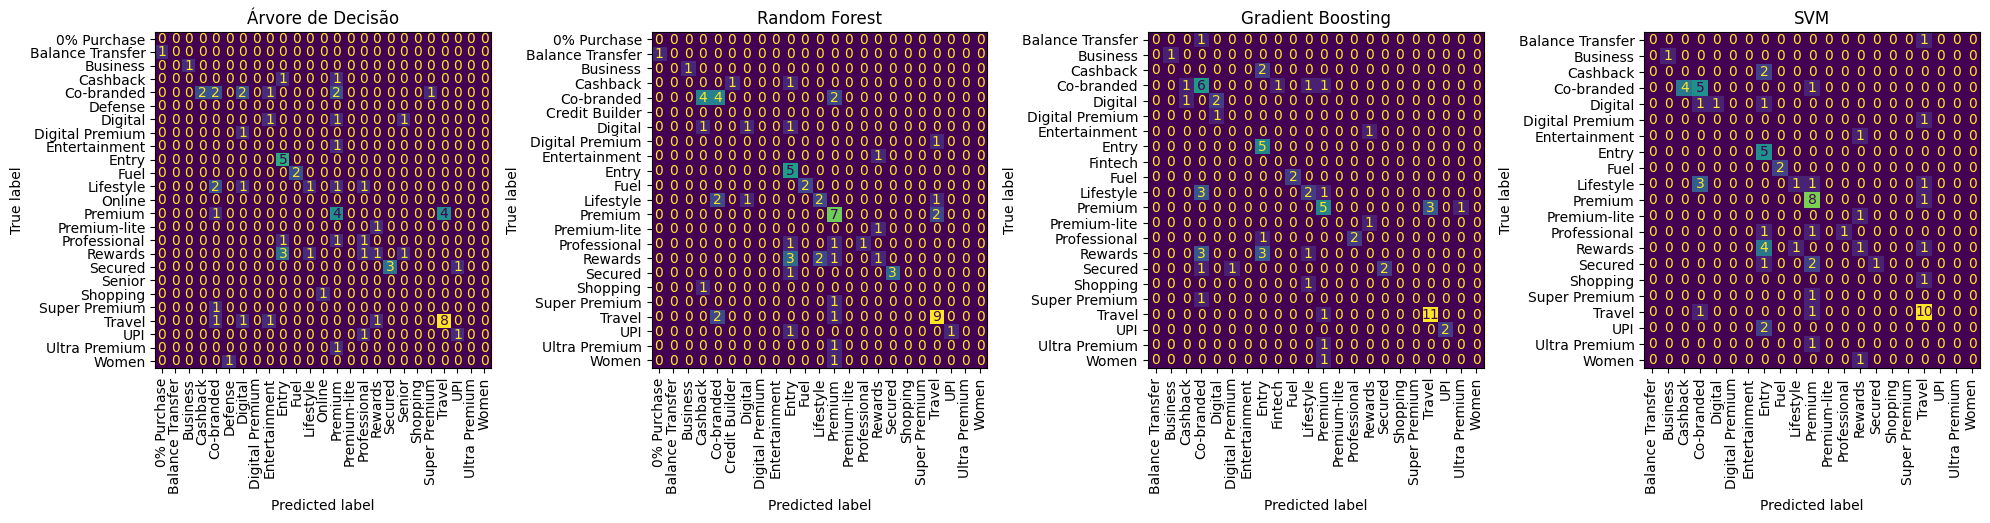

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        ax=ax,
        colorbar=False,
        xticks_rotation='vertical'
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()

9. Validaçao cruzada

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_cv = []

for nome, modelo in modelos.items():
    scores = cross_val_score(
        modelo, x, y, cv=cv, scoring='accuracy'
    )

    resultados_cv.append({
        'Modelo': nome,
        'Acurácia Média': scores.mean(),
        'Desvio Padrão': scores.std()
    })

    print(f'\n{nome}')
    print('Acurácias:', scores)
    print(f'Acurácia média: {scores.mean():.2%}')
    print(f'Desvio padrão: {scores.std():.2%}')

pd.DataFrame(resultados_cv).sort_values(
    'Acurácia Média', ascending=False
)


Árvore de Decisão
Acurácias: [0.39189189 0.52054795 0.52054795 0.53424658 0.43835616]
Acurácia média: 48.11%
Desvio padrão: 5.61%

Random Forest
Acurácias: [0.5        0.5890411  0.57534247 0.63013699 0.53424658]
Acurácia média: 56.58%
Desvio padrão: 4.49%

Gradient Boosting
Acurácias: [0.54054054 0.65753425 0.56164384 0.54794521 0.5890411 ]
Acurácia média: 57.93%
Desvio padrão: 4.25%

SVM
Acurácias: [0.48648649 0.52054795 0.56164384 0.5890411  0.50684932]
Acurácia média: 53.29%
Desvio padrão: 3.73%


,Modelo,Acurácia Média,Desvio Padrão
2,Gradient Boosting,0.579341,0.042456
1,Random Forest,0.565753,0.044935
3,SVM,0.532914,0.037319
0,Árvore de Decisão,0.481118,0.056075


10. Interpretaçao

1. Comparação das acurácias
Na validação cruzada, o Gradient Boosting apresentou o melhor resultado, com média de 57,93% de acurácia. Em seguida, ficou o Random Forest, com 56,58%, o SVM, com 53,29%, e a Árvore de Decisão, com 48,11%.
2. Análise dos resultados
O Gradient Boosting apresentou o melhor desempenho médio entre os quatro modelos, além de um desvio padrão de 4,25%, indicando uma variação relativamente pequena entre as divisões.
O Random Forest também apresentou um resultado próximo, com 56,58% de acurácia média. O SVM alcançou 53,29% e apresentou o menor desvio padrão (3,73%), demonstrando maior estabilidade entre as divisões, embora não tenha obtido a maior acurácia.
Já a Árvore de Decisão apresentou o menor desempenho, com 48,11% de acurácia média e o maior desvio padrão (5,61%), indicando maior variação nos resultados.
3. Conclusão geral
Conclui-se que o Gradient Boosting foi o modelo com melhor desempenho na validação cruzada, alcançando 57,93% de acurácia média. O Random Forest apresentou o segundo melhor resultado, seguido pelo SVM. A Árvore de Decisão obteve o menor desempenho.

Literary Digest Eleição de 1936

1. Carregamento e preparação dos dados

In [76]:
import kagglehub
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [57]:
# Carregar a aba de 1936
df = pd.read_excel('/LitDigestFull.xlsx', sheet_name='1936')

# Visualizar informações
print('Formato:', df.shape)
print('Colunas:', df.columns.tolist())

# Visualizar as primeiras linhas
display(df.head())

Formato: (51, 56)
Colunas: ['Unnamed: 0', 'Unnamed: 1', 'Landon  (R)', 'How did they vote in 1932?', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Roosevelt  (D)', 'How did they vote in 1932?.1', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Lemke (Union)', 'How did they vote in 1932?.2', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'MINOR CANDIDATES', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Grand Total Votes', 'Unnamed: 33', 'State - 1936', 'Electoral votes', 'Roosevelt  ', '%', 'Electoral votes.1', 'Landon   ', '%.1', 'Electoral votes.2', 'Lemke (Union).1', '%.2', 'Electoral votes.3', 'Thomas (Soc.)', '%.3', 'Electoral votes.4', 'Other', '%.4', 'Electoral votes.5', 'Margin', '%.5', 'Total votes', 'State', 'Unnamed: 55']


,Unnamed: 0,Unnamed: 1,Landon (R),How did they vote in 1932?,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,%.3,Electoral votes.4,Other,%.4,Electoral votes.5,Margin,%.5,Total votes,State,Unnamed: 55
0,State,Electoral Vote,Landon,Rep.,Dem.,Soc.,Others,Did Not Vote,Vote Not Indicated,NaN,...,0.09,-,1397,0.51,-,202838.0,73.56,275244.0,AL,https://en.wikipedia.org/wiki/1936_United_Stat...
1,Alabama,11,3060,1218,1298,3,3,412,126,NaN,...,0.26,-,384,0.31,-,53289.0,42.92,124163.0,AZ,NaN
2,Arizona,3,2337,1431,647,18,0,129,112,NaN,...,0.25,-,169,0.09,-,114726.0,63.94,179423.0,AR,NaN
3,Arkansas,9,2724,1338,953,7,9,274,143,NaN,...,0.43,-,24284,0.92,-,930405.0,35.26,2638882.0,CA,NaN
4,California,22,89516,65360,16200,315,53,3519,4069,NaN,...,0.33,-,841,0.17,-,113754.0,23.28,488684.0,CO,NaN


2. Limpeza dos Dados

In [58]:
# Remover a primeira linha, que contém os cabeçalhos internos
df = df.iloc[1:].reset_index(drop=True)

# Remover a coluna que contém o link da Wikipédia
df = df.drop(columns=['Unnamed: 55'], errors='ignore')

# Substituir traços por valores ausentes
df = df.replace('-', pd.NA)

# Remover colunas totalmente vazias
df = df.dropna(axis=1, how='all')

# Conferir o resultado
print("Formato após a limpeza:", df.shape)

display(df.head())

Formato após a limpeza: (50, 48)


/tmp/ipykernel_437/4133224223.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('-', pd.NA)


,Unnamed: 0,Unnamed: 1,Landon (R),How did they vote in 1932?,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Roosevelt (D),...,Lemke (Union).1,%.2,Thomas (Soc.),%.3,Other,%.4,Margin,%.5,Total votes,State
0,Alabama,11,3060,1218,1298,3,3,412,126,10082,...,3307,2.66,317,0.26,384,0.31,53289.0,42.92,124163.0,AZ
1,Arizona,3,2337,1431,647,18,0,129,112,1975,...,4,0,446,0.25,169,0.09,114726.0,63.94,179423.0,AR
2,Arkansas,9,2724,1338,953,7,9,274,143,7608,...,<NA>,<NA>,11331,0.43,24284,0.92,930405.0,35.26,2638882.0,CA
3,California,22,89516,65360,16200,315,53,3519,4069,77245,...,9962,2.04,1593,0.33,841,0.17,113754.0,23.28,488684.0,CO
4,Colorado,6,15949,11872,2714,131,12,637,583,10025,...,21805,3.16,5683,0.82,2421,0.35,103444.0,14.98,690723.0,CT


3. Conferir as colunas da tabela

In [59]:
# Conferir os nomes das colunas
for i, coluna in enumerate(df.columns):
    print(i, coluna)

0 Unnamed: 0
1 Unnamed: 1
2 Landon  (R)
3 How did they vote in 1932?
4 Unnamed: 4
5 Unnamed: 5
6 Unnamed: 6
7 Unnamed: 7
8 Unnamed: 8
9 Roosevelt  (D)
10 How did they vote in 1932?.1
11 Unnamed: 12
12 Unnamed: 13
13 Unnamed: 14
14 Unnamed: 15
15 Unnamed: 16
16 Lemke (Union)
17 How did they vote in 1932?.2
18 Unnamed: 20
19 Unnamed: 21
20 Unnamed: 22
21 Unnamed: 23
22 Unnamed: 24
23 MINOR CANDIDATES
24 Unnamed: 27
25 Unnamed: 28
26 Unnamed: 29
27 Unnamed: 30
28 Unnamed: 31
29 Grand Total Votes
30 State - 1936
31 Electoral votes
32 Roosevelt  
33 %
34 Electoral votes.1
35 Landon   
36 %.1
37 Electoral votes.2
38 Lemke (Union).1
39 %.2
40 Thomas (Soc.)
41 %.3
42 Other
43 %.4
44 Margin
45 %.5
46 Total votes
47 State


4. Organizar os dados

In [60]:
# Selecionar os dados da pesquisa
df_modelo = df.iloc[:, 0:30].copy()

# Selecionar os resultados oficiais da eleição
df_resultado = df.iloc[:, 30:48].copy()

# Conferir as duas tabelas
print("Formato dos dados da pesquisa:", df_modelo.shape)
print("Formato dos resultados oficiais:", df_resultado.shape)

display(df_modelo.head())
display(df_resultado.head())

Formato dos dados da pesquisa: (50, 30)
Formato dos resultados oficiais: (50, 18)


,Unnamed: 0,Unnamed: 1,Landon (R),How did they vote in 1932?,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Roosevelt (D),...,Unnamed: 22,Unnamed: 23,Unnamed: 24,MINOR CANDIDATES,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Grand Total Votes
0,Alabama,11,3060,1218,1298,3,3,412,126,10082,...,0,4,6,33,3,27,0,0,63,13273
1,Arizona,3,2337,1431,647,18,0,129,112,1975,...,0,10,12,22,24,14,0,0,60,4476
2,Arkansas,9,2724,1338,953,7,9,274,143,7608,...,3,9,10,37,5,21,2,5,70,10540
3,California,22,89516,65360,16200,315,53,3519,4069,77245,...,25,163,492,728,967,398,44,60,2197,173935
4,Colorado,6,15949,11872,2714,131,12,637,583,10025,...,2,26,53,122,49,41,10,11,233,26786


,State - 1936,Electoral votes,Roosevelt,%,Electoral votes.1,Landon,%.1,Electoral votes.2,Lemke (Union).1,%.2,Thomas (Soc.),%.3,Other,%.4,Margin,%.5,Total votes,State
0,Arizona,3.0,86722.0,69.85,3,33433.0,26.93,<NA>,3307,2.66,317,0.26,384,0.31,53289.0,42.92,124163.0,AZ
1,Arkansas,9.0,146765.0,81.80,9,32039.0,17.86,<NA>,4,0,446,0.25,169,0.09,114726.0,63.94,179423.0,AR
2,California,22.0,1766836.0,66.95,22,836431.0,31.70,<NA>,<NA>,<NA>,11331,0.43,24284,0.92,930405.0,35.26,2638882.0,CA
3,Colorado,6.0,295021.0,60.37,6,181267.0,37.09,<NA>,9962,2.04,1593,0.33,841,0.17,113754.0,23.28,488684.0,CO
4,Connecticut,8.0,382129.0,55.32,8,278685.0,40.35,<NA>,21805,3.16,5683,0.82,2421,0.35,103444.0,14.98,690723.0,CT


In [61]:
# Recarregar a planilha original
df_original = pd.read_excel('/LitDigestFull.xlsx', sheet_name='1936')

# Separar a pesquisa e os resultados oficiais
df_modelo = df_original.iloc[1:51, 0:30].copy()
df_resultado = df_original.iloc[0:50, 34:55].copy()

# Conferir os resultados
print("Formato dos dados da pesquisa:", df_modelo.shape)
print("Formato dos resultados oficiais:", df_resultado.shape)

display(df_modelo.head())
display(df_resultado.head())

Formato dos dados da pesquisa: (50, 30)
Formato dos resultados oficiais: (50, 21)


,Unnamed: 0,Unnamed: 1,Landon (R),How did they vote in 1932?,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,MINOR CANDIDATES,Unnamed: 27,Unnamed: 28,Unnamed: 29
1,Alabama,11,3060,1218,1298,3,3,412,126,NaN,...,49,4,0,4,6,NaN,33,3,27,0
2,Arizona,3,2337,1431,647,18,0,129,112,NaN,...,52,8,0,10,12,NaN,22,24,14,0
3,Arkansas,9,2724,1338,953,7,9,274,143,NaN,...,98,4,3,9,10,NaN,37,5,21,2
4,California,22,89516,65360,16200,315,53,3519,4069,NaN,...,2560,117,25,163,492,NaN,728,967,398,44
5,Colorado,6,15949,11872,2714,131,12,637,583,NaN,...,333,29,2,26,53,NaN,122,49,41,10


,State - 1936,Electoral votes,Roosevelt,%,Electoral votes.1,Landon,%.1,Electoral votes.2,Lemke (Union).1,%.2,...,Thomas (Soc.),%.3,Electoral votes.4,Other,%.4,Electoral votes.5,Margin,%.5,Total votes,State
0,Alabama,11.0,238136.0,86.38,11,35358.0,12.82,-,551,0.2,...,242,0.09,-,1397,0.51,-,202838.0,73.56,275244.0,AL
1,Arizona,3.0,86722.0,69.85,3,33433.0,26.93,-,3307,2.66,...,317,0.26,-,384,0.31,-,53289.0,42.92,124163.0,AZ
2,Arkansas,9.0,146765.0,81.80,9,32039.0,17.86,-,4,0,...,446,0.25,-,169,0.09,-,114726.0,63.94,179423.0,AR
3,California,22.0,1766836.0,66.95,22,836431.0,31.70,-,-,-,...,11331,0.43,-,24284,0.92,-,930405.0,35.26,2638882.0,CA
4,Colorado,6.0,295021.0,60.37,6,181267.0,37.09,-,9962,2.04,...,1593,0.33,-,841,0.17,-,113754.0,23.28,488684.0,CO


5. Conversão dos Atributos

In [62]:
# Separar atributos (X) e variável alvo (y)
X = df_modelo.iloc[:, 1:].copy()
y = (pd.to_numeric(df_resultado.iloc[:, 2]) >
     pd.to_numeric(df_resultado.iloc[:, 5])).astype(int)

# Converter atributos categóricos de X em numéricos
X = pd.get_dummies(X, drop_first=True)

print("Conversão concluída sem erros!")
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Conversão concluída sem erros!
Formato de X: (50, 1066)
Formato de y: (50,)


6. Divisão em treino e teste

In [63]:
# Divisão dos dados em treinamento e teste em 80% e 20%

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Mostrar resultados da divisão

print("Formato dos dados de treinamento:", X_train.shape)
print("Formato dos dados de teste:", X_test.shape)

print("Formato dos rótulos de treinamento:", y_train.shape)
print("Formato dos rótulos de teste:", y_test.shape)

print("\nDivisão concluída com sucesso!")

Formato dos dados de treinamento: (40, 1066)
Formato dos dados de teste: (10, 1066)
Formato dos rótulos de treinamento: (40,)
Formato dos rótulos de teste: (10,)

Divisão concluída com sucesso!


7. Criação e treinamento dos modelos

In [64]:
# Separando os atributos e a variável que queremos prever
X = df_modelo.iloc[:, 1:]
y = (pd.to_numeric(df_resultado.iloc[:, 2]) >
     pd.to_numeric(df_resultado.iloc[:, 5])).astype(int)

# Convertendo os atributos para numéricos
X = X.apply(pd.to_numeric, errors='coerce')

# Dividindo os dados em treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Tratando os valores ausentes
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# Conferindo se ainda existem colunas de texto
print(X_train.select_dtypes(include=['object']).columns.tolist())

[]


In [65]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado
SVM: treinado


8. Previsões nos dados

In [66]:
previsoes = {nome: modelo.predict(X_test) for nome, modelo in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 13    1
39    1
30    1
45    1
17    1
48    0
26    1
25    1
32    1
19    1
dtype: int64
Árvore de Decisão: [1 1 1 1 1 1 0 1 1 1]
Random Forest: [1 1 1 1 1 1 1 1 1 1]
Gradient Boosting: [1 1 1 1 1 1 0 1 1 1]
SVM: [1 1 1 1 1 1 1 1 1 1]


9. Avaliação e comparação

In [67]:
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 80.00%
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.89      0.89      0.89         9

    accuracy                           0.80        10
   macro avg       0.44      0.44      0.44        10
weighted avg       0.80      0.80      0.80        10


Random Forest — Acurácia: 90.00%
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.90      1.00      0.95         9

    accuracy                           0.90        10
   macro avg       0.45      0.50      0.47        10
weighted avg       0.81      0.90      0.85        10


Gradient Boosting — Acurácia: 80.00%
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.89      0.89      0.89         9

    accuracy                           0.80        10
   macro avg      

,Modelo,Acurácia
1,Random Forest,0.9
3,SVM,0.9
0,Árvore de Decisão,0.8
2,Gradient Boosting,0.8


10. Vizualizações e Previsões

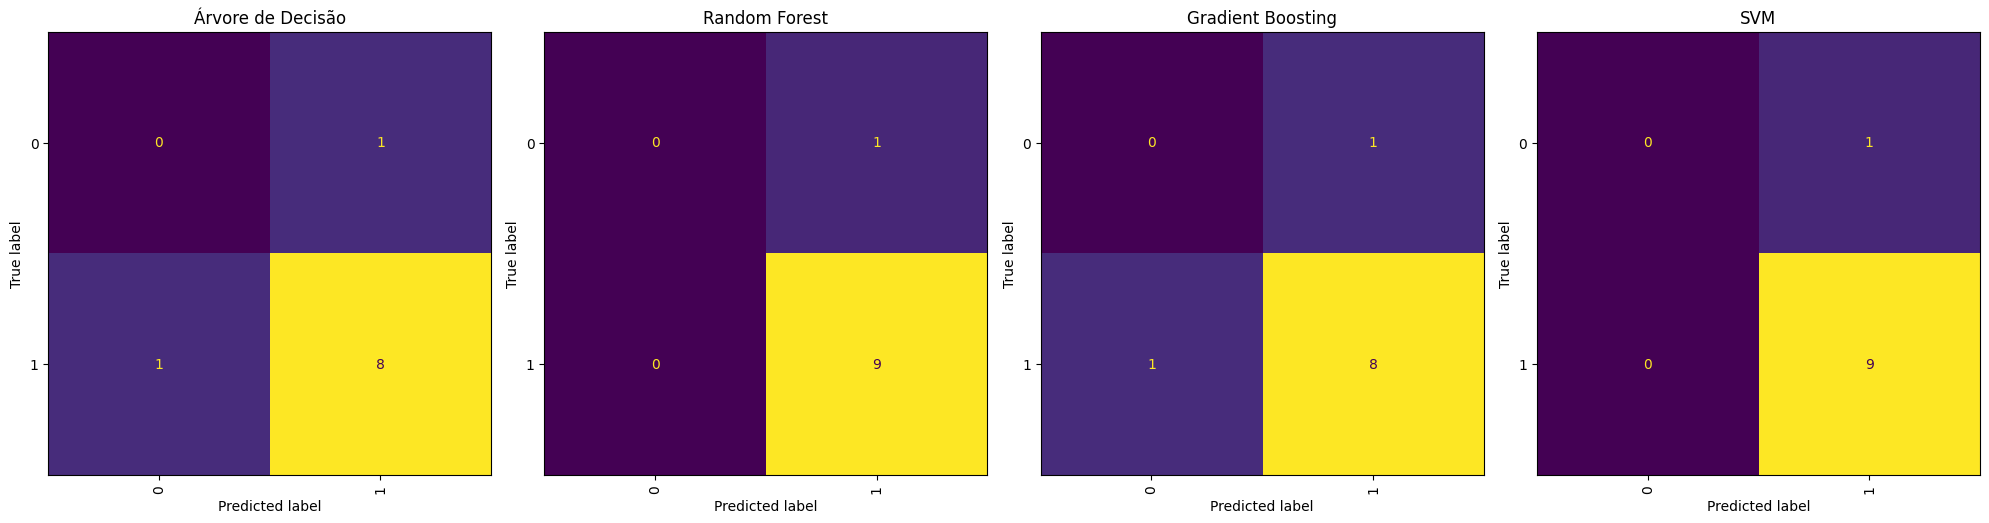

In [68]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        ax=ax,
        colorbar=False,
        xticks_rotation='vertical'
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()

11. Validaçao cruzada

In [78]:
# Criar validação cruzada com 3 divisões

cv = StratifiedKFold(

    n_splits=3,

    shuffle=True,

    random_state=42

)

# Criar modelos com tratamento de valores ausentes

modelos_cv = {

    "Árvore de Decisão": Pipeline([

        ("imputer", SimpleImputer(strategy="median")),

        ("modelo", DecisionTreeClassifier(random_state=42))

    ]),

    "Random Forest": Pipeline([

        ("imputer", SimpleImputer(strategy="median")),

        ("modelo", RandomForestClassifier(

            n_estimators=100,

            random_state=42

        ))

    ]),

    "Gradient Boosting": Pipeline([

        ("imputer", SimpleImputer(strategy="median")),

        ("modelo", GradientBoostingClassifier(random_state=42))

    ]),

    "SVM": Pipeline([

        ("imputer", SimpleImputer(strategy="median")),

        ("scaler", StandardScaler()),

        ("modelo", SVC(random_state=42))

    ])

}

# Executar validação cruzada

resultados_cv = {}

for nome, modelo in modelos_cv.items():

    acuracias = cross_val_score(

        modelo,

        X,

        y,

        cv=cv,

        scoring="accuracy"

    )

    resultados_cv[nome] = {

        "Acurácias": acuracias,

        "Média": acuracias.mean(),

        "Desvio padrão": acuracias.std()

    }

    print("\nModelo:", nome)

    print("Acurácias:", acuracias)

    print(f"Acurácia média: {acuracias.mean():.2%}")

    print(f"Desvio padrão: {acuracias.std():.2%}")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-


Modelo: Árvore de Decisão
Acurácias: [0.88235294 0.94117647 0.9375    ]
Acurácia média: 92.03%
Desvio padrão: 2.69%


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-


Modelo: Random Forest
Acurácias: [0.94117647 0.94117647 0.9375    ]
Acurácia média: 94.00%
Desvio padrão: 0.17%


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-


Modelo: Gradient Boosting
Acurácias: [0.94117647 0.94117647 0.9375    ]
Acurácia média: 94.00%
Desvio padrão: 0.17%

Modelo: SVM
Acurácias: [0.94117647 0.94117647 0.9375    ]
Acurácia média: 94.00%
Desvio padrão: 0.17%


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Unnamed: 9' 'Unnamed: 17' 'Unnamed: 25']. At least one non-

12. interpretaçao

1. Comparação das acurácias
Na validação cruzada com 3 divisões, os resultados foram:
Árvore de Decisão: 92,03% de acurácia média.
Random Forest: 94,00%.
Gradient Boosting: 94,00%.
SVM: 94,00%.
Random Forest, Gradient Boosting e SVM apresentaram os melhores resultados, empatados com 94% de acurácia média.
2. Análise dos resultados
A Árvore de Decisão apresentou um resultado um pouco inferior aos demais modelos, com 92,03% de acurácia e desvio padrão de 2,69%.
Random Forest, Gradient Boosting e SVM tiveram resultados praticamente iguais nas três divisões, com desvio padrão de apenas 0,17%. Isso indica que apresentaram maior estabilidade nessa validação cruzada.
Também apareceram avisos informando que as colunas Unnamed: 9, Unnamed: 17 e Unnamed: 25 estão completamente vazias. Esses avisos não impediram a execução, mas indicam que essas colunas não fornecem informações úteis e podem ser removidas.
3. Conclusão geral
Conclui-se que Random Forest, Gradient Boosting e SVM apresentaram os melhores resultados na validação cruzada, alcançando 94% de acurácia média. A Árvore de Decisão também apresentou um bom desempenho, com 92,03%.